In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt

In [3]:
countries = gpd.read_file('world_1920.geojson')

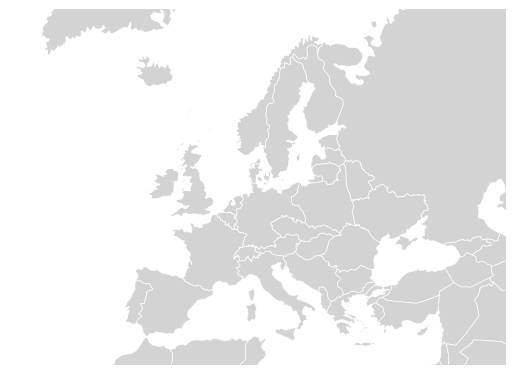

In [4]:
countries = countries.to_crs('EPSG:3035')

fig, ax = plt.subplots()
countries.plot(ax=ax, fc='lightgray', ec='white', lw=0.5)
ax.set_xlim(1172449, 7469550)
ax.set_ylim(1218180, 5735170)
ax.set_axis_off() 

# 1. Save the plot first
plt.savefig("interactions.pdf", format="pdf", bbox_inches="tight")

# 2. Show it on screen last
plt.show()

In [5]:
countries.head()

,NAME,ABBREVN,SUBJECTO,BORDERPRECISION,PARTOF,wikipedia,geometry
0,Luxembourg,Luxembourg,Luxembourg,3,Luxembourg,NaN,"MULTIPOLYGON (((4018642.395 2941288.555, 40240..."
1,Switzerland,Switzerland,Switzerland,3,Switzerland,NaN,"MULTIPOLYGON (((4289606.971 2699582.742, 42804..."
2,France,France,France,3,France,NaN,"MULTIPOLYGON (((4273024.44 2200484.195, 427440..."
3,United Kingdom of Great Britain and Ireland,United Kingdom of Great Britain and Ireland,United Kingdom of Great Britain and Ireland,3,United Kingdom of Great Britain and Ireland,NaN,"MULTIPOLYGON (((6470506.038 1685730.332, 64721..."
4,Bhutan,Bhutan,Bhutan,3,Bhutan,NaN,"MULTIPOLYGON (((10782996.61 4437121.368, 10780..."


In [13]:
gdf = gpd.read_file('world_1920.geojson')


In [14]:
import geopandas as gpd

gdf = gpd.read_file("world_1920.geojson")

# Split into parts, rank by area (equal-area CRS so degrees don't distort sizes)
parts = gdf.explode(index_parts=True).reset_index(names=["feature_id", "part"])
parts["area"] = parts.to_crs("EPSG:6933").area

# Keep the largest part for each original feature
largest = (parts.sort_values("area", ascending=False)
                .drop_duplicates("feature_id"))

# A point guaranteed to fall inside that part
labels = largest.copy()
labels["geometry"] = largest.geometry.representative_point()

labels[["NAME", "area", "geometry"]].to_file("world_1920_labels.geojson", driver="GeoJSON")

In [10]:
gdf.shape

(163, 7)

In [12]:
canada = gdf[gdf['NAME']=='Canada']
canada.head()

,NAME,ABBREVN,SUBJECTO,BORDERPRECISION,PARTOF,wikipedia,geometry
25,Canada,Canada,Canada,3,Canada,NaN,"MULTIPOLYGON (((-126.23254 49.53354, -126.5631..."


In [117]:
import geopandas as gpd

In [150]:
cshapes = gpd.read_file('https://icr.ethz.ch/data/cshapes/CShapes-2.0.geojson')

In [151]:
lakes = gpd.read_file('ne_50m_lakes/ne_50m_lakes.shp')
lakes_union = gpd.GeoDataFrame(geometry=[lakes.union_all()], crs=lakes.crs)
lakes_union.to_file('lakes.geojson', driver='GeoJSON')

<Axes: >

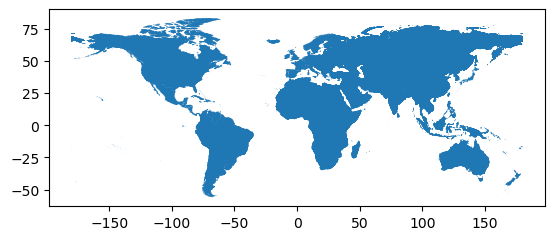

In [152]:
cshapes.plot()

In [153]:
year2019 = cshapes[cshapes['gweyear']==2019]
year2019['geometry'] = year2019['geometry'].make_valid()

/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/constructive.py:752: RuntimeWarning: invalid value encountered in make_valid
  return lib.make_valid(geometry, **kwargs)


In [154]:
year2019 = year2019.dissolve()

/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:553: RuntimeWarning: invalid value encountered in unary_union
  return lib.unary_union(collections, **kwargs)


<Axes: >

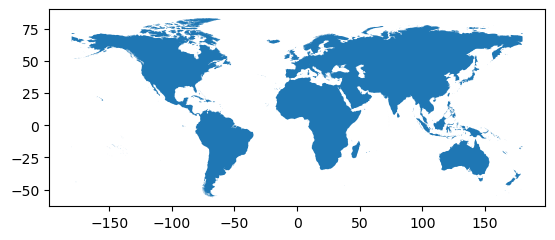

In [155]:
year2019.plot()

In [156]:
year2019.to_file('background.geojson', driver='GeoJSON')

In [157]:
cshapes.to_file('cshapes.geojson')

In [ ]:
import geopandas as gpd
import pandas as pd

gdf = gpd.read_file("cshapes.geojson")

# original cshapes name -> [(first day this name applies, name), ...]
# None = from the start of the record
HISTORY = {
    "Russia (Soviet Union)": [(None, "Russian Empire"), ("1917-11-07", "Russia"),
                              ("1922-12-30", "Union of Soviet Socialist Republics"), ("1991-12-26", "Russian Federation")],
    "Canada": [(None, "Dominion of Canada"), ("1951-01-01", "Canada")],
    "German Federal Republic": [(None, "West Germany"), ("1990-10-03", "Germany")],
    "German Democratic Republic": [(None, "East Germany")],
    "Italy/Sardinia": [(None, "Sardinia-Piedmont"), ("1861-03-17", "Italy")],
    "Turkey (Ottoman Empire)": [(None, "Ottoman Empire"), ("1923-10-29", "Turkey")],
    "Yemen (Arab Republic of Yemen)": [(None, "Kingdom of Yemen"), ("1962-09-27", "North Yemen"),
                                       ("1990-05-22", "Yemen")],
    "Cambodia (Kampuchea)": [(None, "Cambodia"), ("1970-10-09", "Khmer Republic"),
                             ("1975-04-17", "Kampuchea"), ("1989-04-30", "Cambodia")],
    "Sri Lanka (Ceylon)": [(None, "Ceylon"), ("1972-05-22", "Sri Lanka")],
    "Madagascar (Malagasy)": [(None, "Madagascar"), ("1960-06-26", "Malagasy Republic"),
                              ("1975-12-30", "Madagascar")],
    "Swaziland (Eswatini)": [(None, "Swaziland"), ("2018-04-19", "Eswatini")],
    "Tanzania (Tanganyika)": [(None, "Tanganyika"), ("1964-04-26", "Tanzania")],
    "Burkina Faso (Upper Volta)": [(None, "Upper Volta"), ("1984-08-04", "Burkina Faso")],
    "Zimbabwe (Rhodesia)": [(None, "Rhodesia"), ("1980-04-18", "Zimbabwe")],
    "Congo, Democratic Republic of (Zaire)": [(None, "Congo Free State"),                   
                                          ("1908-11-15", "Belgian Congo"),
                                          ("1960-06-30", "Republic of the Congo"),        
                                          ("1964-08-01", "Democratic Republic of the Congo"),
                                          ("1971-10-27", "Zaire"),
                                          ("1997-05-17", "Democratic Republic of the Congo")],
    "Iran (Persia)": [(None, "Persia"), ("1935-03-21", "Imperial State of Iran"), ("1979-02-11", "Islamic Republic of Iran")],
    "Ghana": [(None, "Gold Coast"), ("1957-03-06", "Ghana")],
    "Benin": [(None, "Dahomey"), ("1975-11-30", "Benin")],
    "Cote D'Ivoire": [(None, "Ivory Coast"), ("1985-10-01", "Côte d'Ivoire")],
    "Egypt": [(None, "Egypt"), ("1958-02-01", "United Arab Republic"),
              ("1971-09-02", "Egypt")],
    "Syria": [(None, "Syria"), ("1958-02-01", "United Arab Republic"),
              ("1961-09-28", "Syria")],
    "Lesotho": [(None, "Basutoland"), ("1966-10-04", "Lesotho")],
    "Namibia": [(None, "South West Africa"), ("1990-03-21", "Namibia")],
    "Equatorial Guinea": [(None, "Spanish Guinea"), ("1968-10-12", "Equatorial Guinea")],
    "Botswana": [(None, "Bechuanaland"), ("1966-09-30", "Botswana")],
    "Germany (Prussia)": [(None, "German Reich"), ("1943-06-26", "Greater German Reich")],
    "Myanmar (Burma)": [(None, "Burma"), ("1989-06-18", "Myanmar")],
    "Vietnam (Annam/Cochin China/Tonkin)": [(None, "Đại Nam"),                                  
                                        ("1887-10-17", "French Indochina"),  
                                        ("1945-03-11", "Empire of Vietnam"),                    
                                        ("1945-09-02", "Democratic Republic of Vietnam"),       
                                        ("1976-07-02", "Socialist Republic of Vietnam")],        
    "Thailand": [(None, "Siam"), ("1939-06-24", "Thailand")],
    "Guinea-Bissau": [(None, "Portuguese Guinea"), ('1973-09-24', 'Guinea-Bissau')],
    "Guinea": [(None, "French Guinea"), ('1958-10-02', "Guinea")],
    "Mali": [(None, "French Sudan"), ('1959-04-04', "Mali")],
    "India": [(None, "British Raj"), ('1947-08-15', "India")],
    # plain renames, no split
    "Belarus (Byelorussia)": [(None, "Belarus")],
    "Israel": [(None, "Israel")],
    "Rumania": [(None, "Romania")],
    "New Guinea (German New Guinea) (Kaiser Wilhemsland)": [(None, "Kaiser Wilhelmsland")],
    "Austria-Hungary": [(None, "Austro-Hungarian Monarchy")],
    "Suriname": [(None, "Suriname")],
    "British Somaliland (Somaliland Republic)": [(None, "British Somaliland")],
    "Newfoundland": [(None, "Dominion of Newfoundland")]
}

DAY = pd.Timedelta(days=1)

# Real dates from the numeric columns (the gwsdate/gwedate strings are timezone-shifted)
gdf["_start"] = pd.to_datetime(dict(year=gdf.gwsyear, month=gdf.gwsmonth, day=gdf.gwsday))
gdf["_end"]   = pd.to_datetime(dict(year=gdf.gweyear, month=gdf.gwemonth, day=gdf.gweday))

rows = []
for _, row in gdf.iterrows():
    periods = HISTORY.get(row["cntry_name"])
    if periods is None:
        rows.append(row)
        continue

    starts = [pd.Timestamp(d) if d else pd.Timestamp.min for d, _ in periods]
    ends = [s - DAY for s in starts[1:]] + [pd.Timestamp.max]

    for (_, name), p_start, p_end in zip(periods, starts, ends):
        s, e = max(row["_start"], p_start), min(row["_end"], p_end)
        if s > e:                      # this name doesn't overlap the record
            continue
        new = row.copy()
        new["cntry_name"], new["_start"], new["_end"] = name, s, e
        rows.append(new)

out = gpd.GeoDataFrame(pd.DataFrame(rows).reset_index(drop=True),
                       geometry="geometry", crs=gdf.crs)

# Write the clipped dates back into the columns the map reads
out["gwsyear"], out["gwsmonth"], out["gwsday"] = out._start.dt.year, out._start.dt.month, out._start.dt.day
out["gweyear"], out["gwemonth"], out["gweday"] = out._end.dt.year, out._end.dt.month, out._end.dt.day

# gwsdate/gwedate would now be stale, so drop them along with the helpers
out = out.drop(columns=["_start", "_end", "gwsdate", "gwedate"], errors="ignore")
out.to_file("cshapes_renamed.geojson", driver="GeoJSON")

In [168]:
import geopandas as gpd
from shapely.ops import polylabel

gdf = gpd.read_file("cshapes_renamed.geojson")

# Work in an equal-area projection so "largest part" and label placement are sensible
proj = gdf.to_crs("EPSG:6933")

def label_point(geom):
    # Largest polygon of the multipolygon
    parts = list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]
    biggest = max(parts, key=lambda p: p.area)
    # Pole of inaccessibility: the point furthest from any edge, so it always
    # falls inside the polygon (a centroid can land outside concave shapes)
    return polylabel(biggest, tolerance=1000), biggest.area

pts = proj.geometry.apply(label_point)
labels = proj.copy()
labels["geometry"] = [p[0] for p in pts]
labels["area_km2"] = [p[1] / 1e6 for p in pts]
labels = labels.set_crs("EPSG:6933").to_crs("EPSG:4326")

from shapely.geometry import Point

OVERRIDES = {
    20: (-100, 58),   # Canada
}

for code, (lon, lat) in OVERRIDES.items():
    mask = labels.gwcode == code
    labels.loc[mask, "geometry"] = [Point(lon, lat)] * mask.sum()

# Precompute the numeric dates the time filter uses
ymd = lambda y, m, d: y * 10000 + m * 100 + d
labels["_s"] = [ymd(*r) for r in zip(labels.gwsyear, labels.gwsmonth, labels.gwsday)]
labels["_e"] = [ymd(*r) for r in zip(labels.gweyear, labels.gwemonth, labels.gweday)]

# Keep the file small: only what the label layer needs
labels = labels[["cntry_name", "gwcode", "area_km2", "_s", "_e", "geometry"]]
labels.to_file("cshapes_labels.geojson", driver="GeoJSON")

/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/constructive.py:1493: RuntimeWarning: invalid value encountered in maximum_inscribed_circle
  return lib.maximum_inscribed_circle(geometry, tolerance, **kwargs)


In [160]:
world2019

,cntry_name,area,capname,caplong,caplat,gwcode,gwsdate,gwsyear,gwsmonth,gwsday,gwedate,gweyear,gwemonth,gweday,cap_geom,geometry
0,United States of America,7940050.00,Washington,-77.0367,38.89500,2,31.12.1885 23:00:00,1886,1,1,01.01.1959 23:00:00,1959,1,2,SRID=4326;POINT (-77.03666687011719 38.8950004...,"MULTIPOLYGON (((-75.48306 35.34583, -75.44749 ..."
1,United States of America,9446290.00,Washington,-77.0367,38.89500,2,02.01.1959 23:00:00,1959,1,3,19.08.1959 23:00:00,1959,8,20,SRID=4326;POINT (-77.03666687011719 38.8950004...,"MULTIPOLYGON (((-87.45593 30.29871, -87.33416 ..."
2,United States of America,9462980.00,Washington,-77.0367,38.89500,2,20.08.1959 23:00:00,1959,8,21,30.12.2019 23:00:00,2019,12,31,SRID=4326;POINT (-77.03666687011719 38.8950004...,"MULTIPOLYGON (((-155.00558 19.32888, -154.8320..."
3,Alaska,1506240.00,Juneau,-134.4120,58.30430,3,31.12.1885 23:00:00,1886,1,1,01.01.1959 23:00:00,1959,1,2,SRID=4326;POINT (-134.41201782226562 58.304340...,"MULTIPOLYGON (((-177.8139 51.7197, -177.79724 ..."
4,Hawaii,16685.60,Honolulu,-157.8560,21.30750,4,05.07.1898 23:00:00,1898,7,6,19.08.1959 23:00:00,1959,8,20,SRID=4326;POINT (-157.85595703125 21.307460784...,"MULTIPOLYGON (((-155.00558 19.32888, -154.8320..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
705,"Kashmir (North, Azad)",81688.60,Gilgit,74.4643,35.88190,7708,14.08.1947 23:00:00,1947,8,15,03.01.1949 23:00:00,1949,1,4,SRID=4326;POINT (74.46430206298828 35.88190078...,"POLYGON ((73.63968 36.90106, 73.70619 36.85672..."
706,Perak,18099.70,Taiping,100.7200,4.86496,8201,31.12.1885 23:00:00,1886,1,1,29.06.1896 23:00:00,1896,6,30,SRID=4326;POINT (100.7199935913086 4.864960193...,"POLYGON ((101.568 5.26267, 101.55873 5.28569, ..."
707,Selangore,6856.45,Kuala Lumpur,101.7000,3.16667,8202,31.12.1885 23:00:00,1886,1,1,29.06.1896 23:00:00,1896,6,30,SRID=4326;POINT (101.69998168945312 3.16667008...,"POLYGON ((101.81576 3.31562, 101.79573 3.33383..."
708,Pahang,36294.20,Pekan,103.3900,3.49210,8203,31.12.1887 23:00:00,1888,1,1,29.06.1896 23:00:00,1896,6,30,SRID=4326;POINT (103.38954162597656 3.49210000...,"MULTIPOLYGON (((104.16164 2.70792, 104.21632 2..."


In [161]:
countries = gpd.read_file('ne_50m_admin_0_countries/ne_50m_admin_0_countries.shp')

In [162]:
extras = countries[countries['NAME'].isin(['Greenland'])]
ant = countries[countries['NAME'] == 'Antarctica']
extras.to_file('extras.geojson', driver='GeoJSON')
ant.to_file('ant.geojson', driver='GeoJSON')

<Axes: >

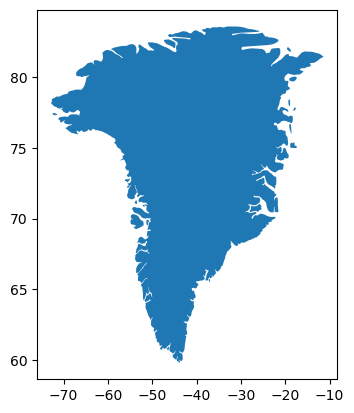

In [102]:
extras.plot()

<Axes: >

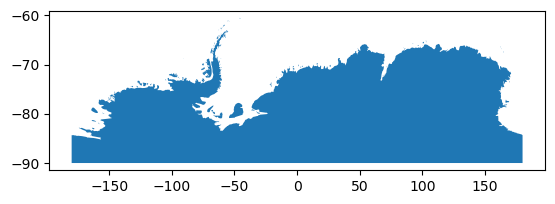

In [104]:
ant.plot()